# 01. EDA

가이드 1~6단계: 데이터 확인, 클래스 분포, 이미지 관찰, ImageNet 비교, 상황 분석

## 0. 공통 설정

In [1]:
import sys, os
sys.path.append(os.path.abspath(".."))   # notebooks/ 에서 src/ 를 import 하기 위함

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.utils import ROOT, DATA_DIR, FIG_DIR, RESULT_DIR, CLASS_NAMES, set_seed, setup_korean_font, save_fig

SEED = 42
set_seed(SEED)
setup_korean_font()
print("프로젝트 루트:", ROOT)

프로젝트 루트: /Users/adj/Team_Project


## 1. 데이터 준비 및 무결성 확인

CSV의 모든 경로에 실제 파일이 있는지, 열리지 않는 파일은 없는지 확인합니다.
학습 도중 에러로 멈추는 것을 막기 위해 처음에 한 번 전수 검사합니다.

In [2]:
meta = pd.read_csv(DATA_DIR / "metadata.csv", encoding="utf-8-sig")
class_map = pd.read_csv(DATA_DIR / "class_mapping.csv", encoding="utf-8-sig")

print("CSV 행 수:", len(meta))          # 기대값 12842
print(meta["split"].value_counts())     # train 8523 / val 1722 / test 2597
class_map

CSV 행 수: 12842
split
train    8523
test     2597
val      1722
Name: count, dtype: int64


,target_id,category,class_name_ko
0,0,dress,원피스
1,1,jacket,재킷
2,2,pants,바지
3,3,skirt,스커트
4,4,top,상의


In [3]:
from PIL import Image
from tqdm.auto import tqdm

missing, broken = [], []
for p in tqdm(meta["image_path"], desc="파일 검사"):
    full = DATA_DIR / p
    if not full.exists():
        missing.append(p)
        continue
    try:
        with Image.open(full) as im:
            im.verify()
    except Exception:
        broken.append(p)

print("누락 파일:", len(missing))
print("손상 파일:", len(broken))

파일 검사:   0%|          | 0/12842 [00:00<?, ?it/s]

누락 파일: 0
손상 파일: 0


## 2. 데이터 개수 및 클래스 분포

(다음 단계에서 작성)

In [4]:
# 클래스 순서를 target_id(0~4) 기준으로 고정, 한글 이름으로 표시
order = class_map.sort_values("target_id")["category"].tolist()
ko = dict(zip(class_map["category"], class_map["class_name_ko"]))
splits = ["train", "val", "test"]

count_tbl = pd.crosstab(meta["category"], meta["split"]).loc[order, splits]
count_tbl.index = [ko[c] for c in count_tbl.index]
count_tbl["total"] = count_tbl.sum(axis=1)
count_tbl.loc["합계"] = count_tbl.sum()

print("분할 비율(%):")
print((meta["split"].value_counts(normalize=True)[splits] * 100).round(1))
count_tbl

분할 비율(%):
split
train    66.4
val      13.4
test     20.2
Name: proportion, dtype: float64


split,train,val,test,total
원피스,1736,346,533,2615
재킷,1615,331,502,2448
바지,1670,340,503,2513
스커트,1834,362,558,2754
상의,1668,343,501,2512
합계,8523,1722,2597,12842


저장됨: figures/02_class_split_counts.png


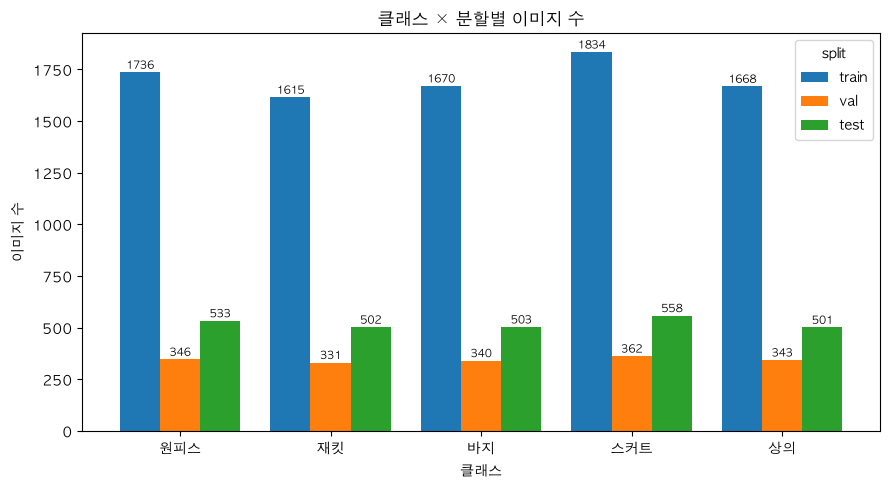

In [5]:
plot_tbl = count_tbl.drop(index="합계")[splits]

fig, ax = plt.subplots(figsize=(9, 5))
plot_tbl.plot(kind="bar", ax=ax, rot=0, width=0.8)
for container in ax.containers:
    ax.bar_label(container, fontsize=8)      # 막대 위에 실제 개수 표시
ax.set_title("클래스 × 분할별 이미지 수")
ax.set_xlabel("클래스")
ax.set_ylabel("이미지 수")
plt.tight_layout()
save_fig("02_class_split_counts")
plt.show()

In [6]:
# 최다/최소 비율: 크면(예: 10배) 가중치·샘플링 필요, 1에 가까우면 균형
train_cnt = count_tbl.drop(index="합계")["train"]
imb_ratio = train_cnt.max() / train_cnt.min()
print(f"Train 최다/최소 비율: {imb_ratio:.2f}배 "
      f"({train_cnt.idxmax()} {train_cnt.max()} / {train_cnt.idxmin()} {train_cnt.min()})")

# 분할마다 클래스 비율이 같은지: 같아야 Val 결과가 Test에서도 재현됨
ratio_tbl = pd.crosstab(meta["category"], meta["split"], normalize="columns").loc[order, splits]
ratio_tbl.index = [ko[c] for c in ratio_tbl.index]
(ratio_tbl * 100).round(1)

Train 최다/최소 비율: 1.14배 (스커트 1834 / 재킷 1615)


split,train,val,test
원피스,20.4,20.1,20.5
재킷,18.9,19.2,19.3
바지,19.6,19.7,19.4
스커트,21.5,21.0,21.5
상의,19.6,19.9,19.3


In [7]:
# 같은 상품이 여러 분할에 들어가면 '옷 종류'가 아니라 '그 상품'을 외워서 맞히는 누수 발생 → 0이어야 함
split_per_product = meta.groupby("product_id")["split"].nunique()
print("전체 상품 수:", meta["product_id"].nunique())
print("여러 분할에 걸친 상품 수:", (split_per_product > 1).sum())

# 상품 1개당 이미지 수
img_per_product = meta.groupby("product_id").size()
print("\n상품당 이미지 수 분포:")
print(img_per_product.value_counts().sort_index().rename("상품 수"))

전체 상품 수: 7495
여러 분할에 걸친 상품 수: 0

상품당 이미지 수 분포:
1    2148
2    5347
Name: 상품 수, dtype: int64


category
원피스    6
재킷     7
바지     8
스커트    4
상의     6
Name: 하위분류 수, dtype: int64
저장됨: figures/02_subcategory_counts.png


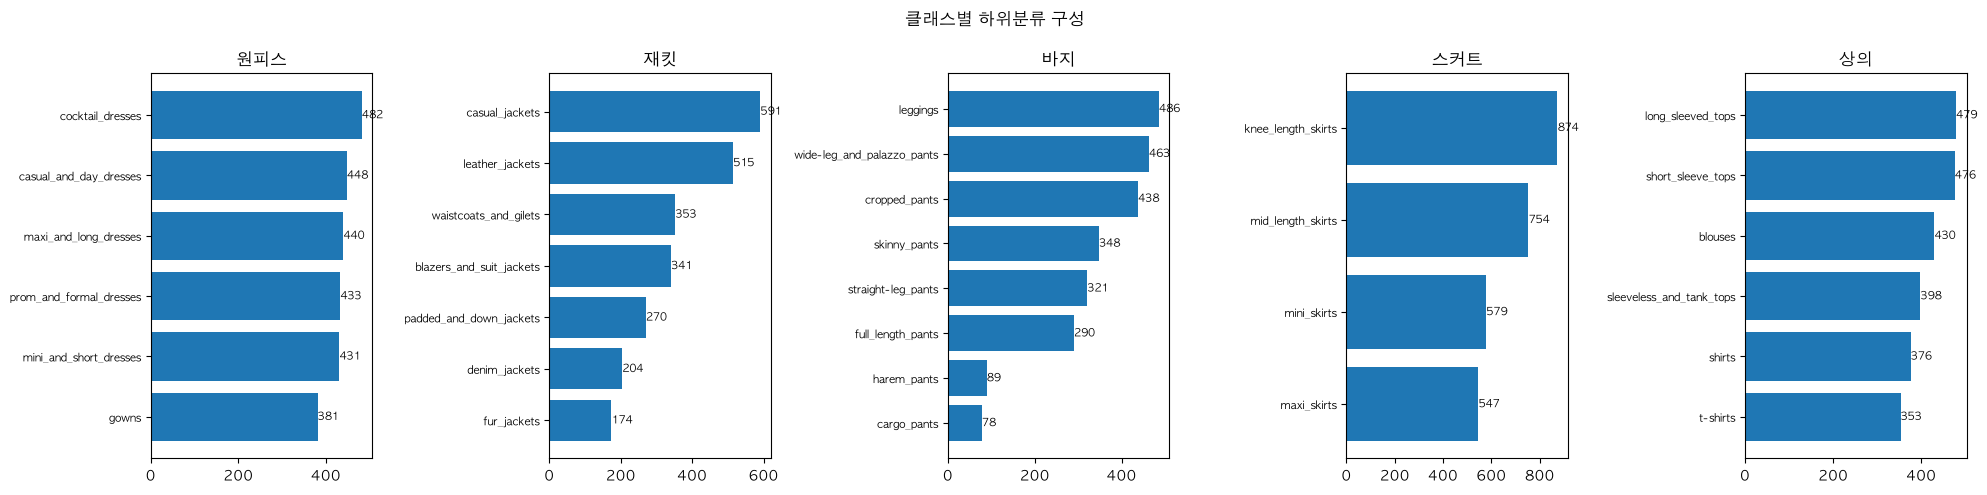

In [8]:
# subcategory는 모델 입력 금지. 클래스 내부 다양성 파악 및 오분류 가설용으로만 사용
print(meta.groupby("category")["subcategory"].nunique().loc[order].rename(index=ko).rename("하위분류 수"))

sub = (meta.groupby("category")["subcategory"].value_counts()
       .rename("이미지 수").reset_index())
sub["클래스"] = sub["category"].map(ko)

fig, axes = plt.subplots(1, 5, figsize=(20, 5))
for ax, cat in zip(axes, order):
    d = sub[sub["category"] == cat].sort_values("이미지 수")
    ax.barh(d["subcategory"], d["이미지 수"])
    ax.bar_label(ax.containers[0], fontsize=8)
    ax.set_title(ko[cat])
    ax.tick_params(axis="y", labelsize=8)
plt.suptitle("클래스별 하위분류 구성")
plt.tight_layout()
save_fig("02_subcategory_counts")
plt.show()

### 2단계 정리
- 전체 12,842장 (train 8,523 / val 1,722 / test 2,597, 약 66:13:20), 5개 클래스
- Train 최다/최소 비율 1.14배(스커트/재킷) → 불균형 거의 없음, 별도 가중치·샘플링 없이 진행
- 세 분할의 클래스 비율 18.9~21.5%로 동일 → Val 결과가 Test에서도 재현될 가능성 높음
- 상품 7,495개, 여러 분할에 걸친 상품 0개 → 상품 단위 누수 없음 (모델·브랜드 단위 분리는 미보장 → 한계)
- 클래스별 하위분류 4~8종으로 클래스 내 다양성 큼. 조끼↔민소매 상의, 맥시 스커트↔맥시 원피스 등이 오분류 후보

## 3. 클래스별 이미지 관찰

(다음 단계에서 작성)

저장됨: figures/03_class_samples_grid.png


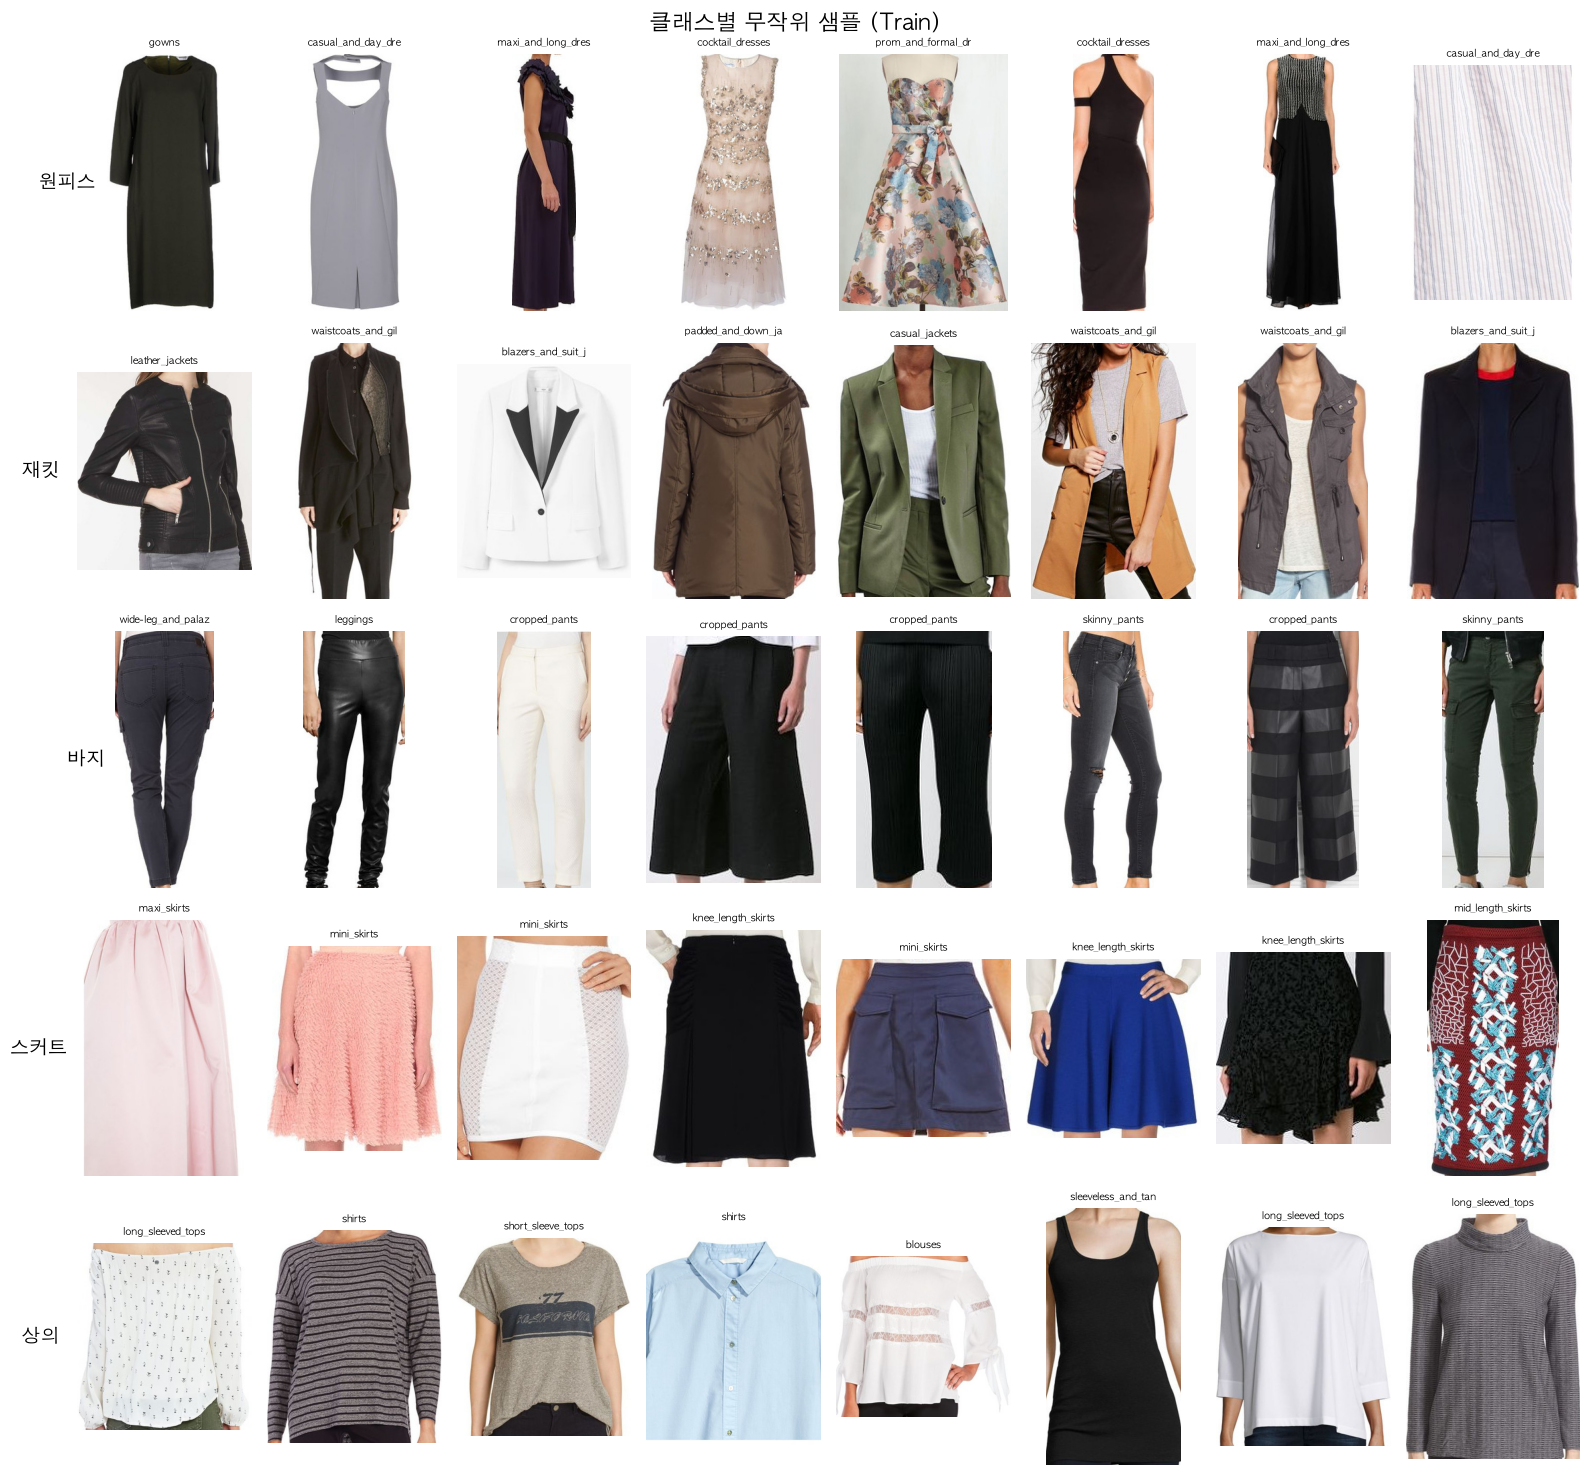

In [9]:
from PIL import Image

# 관찰은 Train에서만: Val/Test를 보고 판단하면 평가 데이터 정보가 결정에 섞임
train = meta[meta["split"] == "train"].copy()

N = 8
fig, axes = plt.subplots(len(order), N, figsize=(N * 2, len(order) * 3))
for r, cat in enumerate(order):
    sample = train[train["category"] == cat].sample(N, random_state=SEED)
    for ax, (_, row) in zip(axes[r], sample.iterrows()):
        ax.imshow(Image.open(DATA_DIR / row["image_path"]).convert("RGB"))
        ax.set_title(row["subcategory"][:18], fontsize=7)
        ax.axis("off")
    axes[r, 0].text(-0.1, 0.5, ko[cat], transform=axes[r, 0].transAxes,
                    fontsize=14, ha="right", va="center")
plt.suptitle("클래스별 무작위 샘플 (Train)", fontsize=16)
plt.tight_layout()
save_fig("03_class_samples_grid")
plt.show()

저장됨: figures/03_confusing_pairs.png


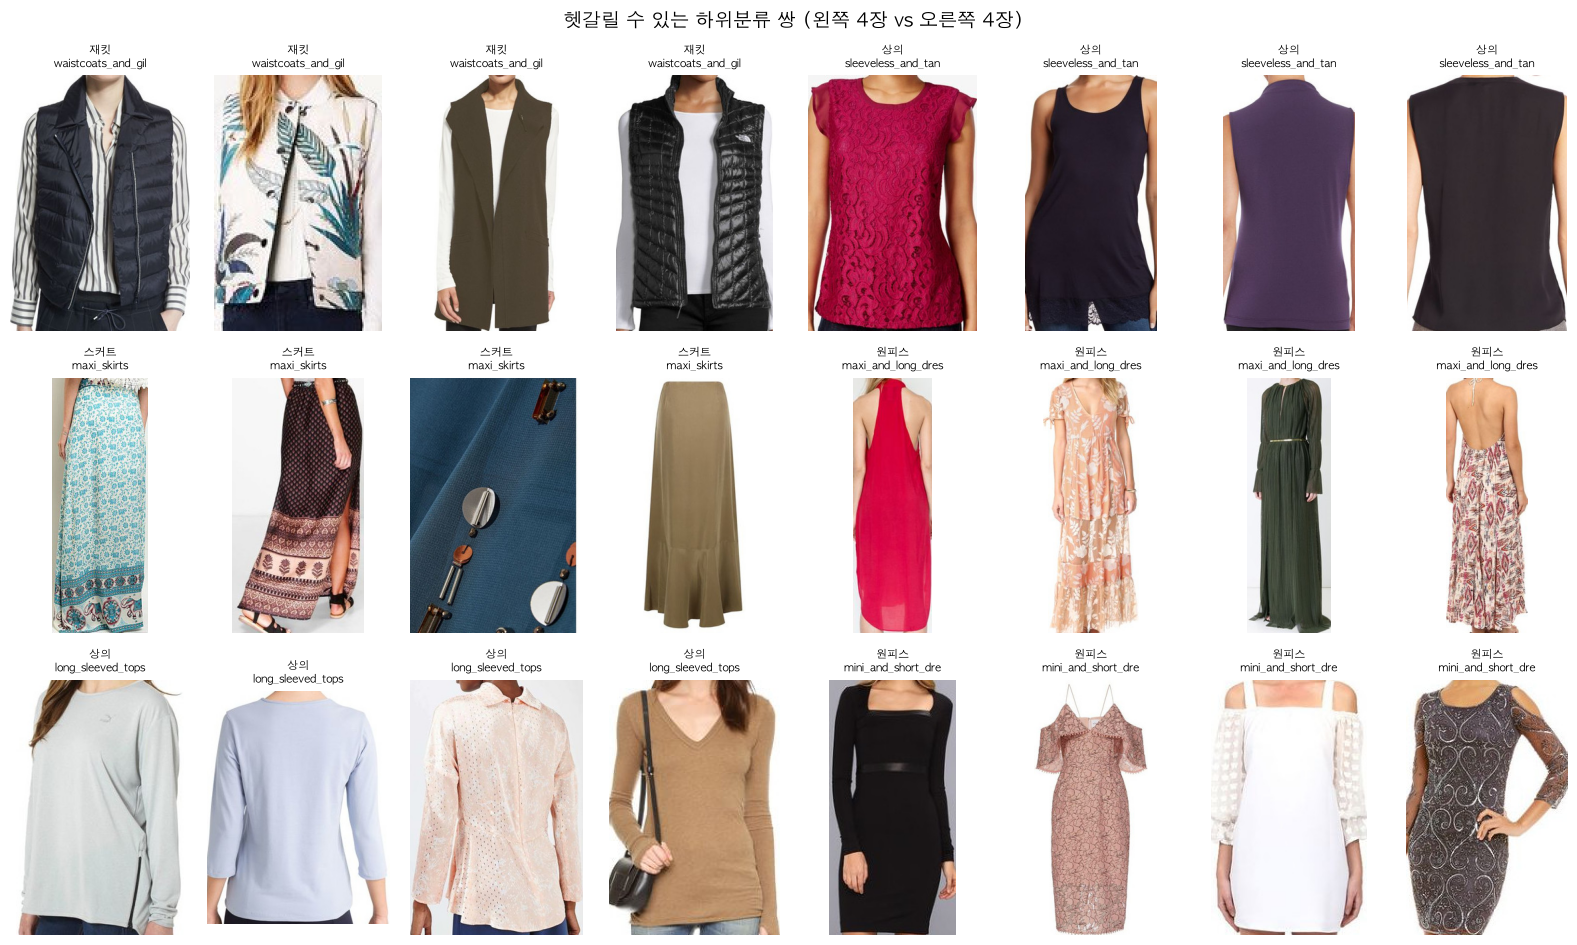

In [10]:
pairs = [
    (("jacket", "waistcoats_and_gilets"), ("top", "sleeveless_and_tank_tops")),
    (("skirt", "maxi_skirts"),            ("dress", "maxi_and_long_dresses")),
    (("top", "long_sleeved_tops"),        ("dress", "mini_and_short_dresses")),
]
K = 4   # 쌍마다 각 4장

fig, axes = plt.subplots(len(pairs), K * 2, figsize=(K * 4, len(pairs) * 3.2))
for r, (a, b) in enumerate(pairs):
    imgs = []
    for cat, sub in (a, b):
        s = train[(train["category"] == cat) & (train["subcategory"] == sub)].sample(K, random_state=SEED)
        imgs += [(ko[cat], sub, p) for p in s["image_path"]]
    for ax, (k, sub, p) in zip(axes[r], imgs):
        ax.imshow(Image.open(DATA_DIR / p).convert("RGB"))
        ax.set_title(f"{k}\n{sub[:18]}", fontsize=8)
        ax.axis("off")
plt.suptitle("헷갈릴 수 있는 하위분류 쌍 (왼쪽 4장 vs 오른쪽 4장)", fontsize=14)
plt.tight_layout()
save_fig("03_confusing_pairs")
plt.show()

In [14]:
# 가설 검증: 헷갈릴 것 같은 쌍의 세로/가로 비율 비교 (몸 좌표가 없으므로 비율을 대리 지표로 사용)
check_pairs = [
    ("waistcoats_and_gilets", "sleeveless_and_tank_tops"),
    ("maxi_skirts", "maxi_and_long_dresses"),
    ("long_sleeved_tops", "mini_and_short_dresses"),
    ("wide-leg_and_palazzo_pants", "maxi_skirts"),
]
train["aspect"] = train["height"] / train["width"]

rows = []
for a, b in check_pairs:
    qa = train.loc[train["subcategory"] == a, "aspect"].quantile([0.25, 0.5, 0.75])
    qb = train.loc[train["subcategory"] == b, "aspect"].quantile([0.25, 0.5, 0.75])
    rows.append({"쌍": f"{a} vs {b}",
                 "A 중앙값": round(qa[0.5], 2), "B 중앙값": round(qb[0.5], 2),
                 "중앙값 차이": round(abs(qa[0.5] - qb[0.5]), 2),
                 "A 범위(25~75%)": f"{qa[0.25]:.2f}~{qa[0.75]:.2f}",
                 "B 범위(25~75%)": f"{qb[0.25]:.2f}~{qb[0.75]:.2f}"})
pd.DataFrame(rows).sort_values("중앙값 차이")

,쌍,A 중앙값,B 중앙값,중앙값 차이,A 범위(25~75%),B 범위(25~75%)
0,waistcoats_and_gilets vs sleeveless_and_tank_tops,1.67,1.69,0.02,1.49~1.92,1.51~1.85
3,wide-leg_and_palazzo_pants vs maxi_skirts,2.43,2.27,0.16,1.97~2.76,1.86~2.59
2,long_sleeved_tops vs mini_and_short_dresses,1.38,1.90,0.52,1.24~1.54,1.71~2.15
1,maxi_skirts vs maxi_and_long_dresses,2.27,2.84,0.57,1.86~2.59,2.47~3.23


In [11]:
meta["aspect"] = meta["height"] / meta["width"]   # 1보다 크면 세로로 긴 이미지

size_tbl = (meta.groupby("category")[["width", "height", "aspect"]]
            .median().loc[order].rename(index=ko).round(2))
print("짧은 변 100px 미만 이미지:", (meta[["width", "height"]].min(axis=1) < 100).sum(), "장")
print("가로가 세로보다 긴 이미지:", (meta["width"] > meta["height"]).sum(), "장")
print("세로가 최대값 384px인 비율:", round((meta["height"] == 384).mean() * 100, 1), "%")
size_tbl

짧은 변 100px 미만 이미지: 112 장
가로가 세로보다 긴 이미지: 366 장
세로가 최대값 384px인 비율: 64.3 %


,width,height,aspect
category,,,
원피스,157.0,384.0,2.28
재킷,247.0,384.0,1.45
바지,149.0,384.0,2.46
스커트,198.0,364.0,1.57
상의,251.0,384.0,1.41


저장됨: figures/03_size_aspect.png


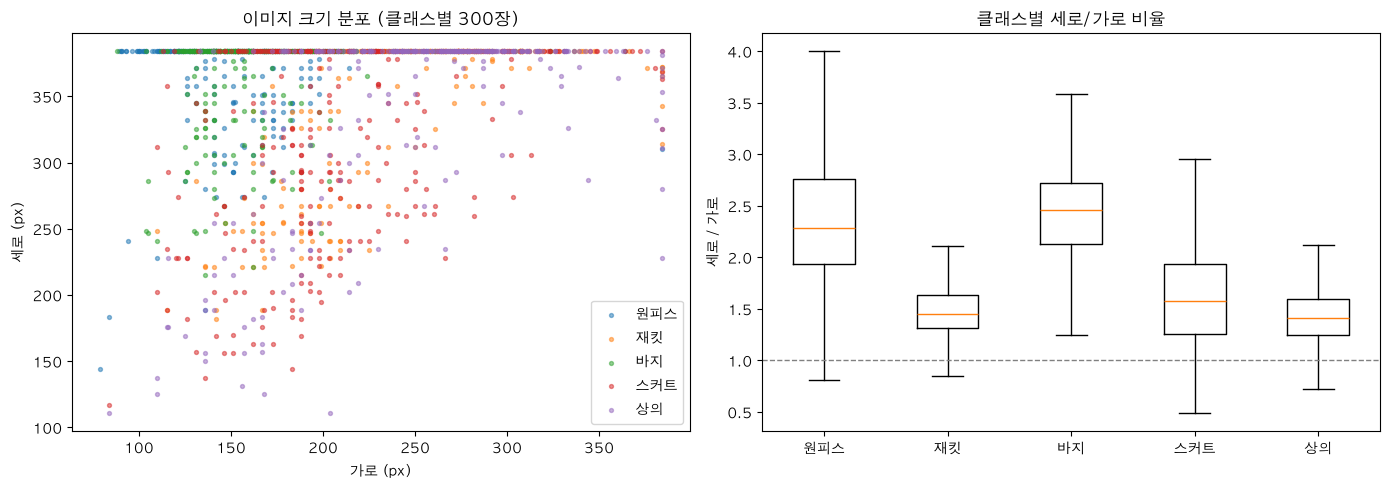

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (왼쪽) 가로 × 세로 좌표: 클래스별로 점이 모이는 위치가 다른지
for cat in order:
    d = train[train["category"] == cat].sample(300, random_state=SEED)
    axes[0].scatter(d["width"], d["height"], s=8, alpha=0.5, label=ko[cat])
axes[0].set_xlabel("가로 (px)")
axes[0].set_ylabel("세로 (px)")
axes[0].set_title("이미지 크기 분포 (클래스별 300장)")
axes[0].legend()

# (오른쪽) 세로/가로 비율 분포
data = [meta.loc[meta["category"] == c, "aspect"] for c in order]
axes[1].boxplot(data, tick_labels=[ko[c] for c in order], showfliers=False)
axes[1].axhline(1, color="gray", ls="--", lw=1)        # 정사각형 기준선
axes[1].set_ylabel("세로 / 가로")
axes[1].set_title("클래스별 세로/가로 비율")

plt.tight_layout()
save_fig("03_size_aspect")
plt.show()

In [13]:
from collections import Counter

# 값이 하나뿐인 열은 분석에 쓸 정보가 없음
print(meta["image_source"].value_counts(), "\n")
print(meta["crop_applied"].value_counts(), "\n")

# RGB가 아닌 이미지(흑백 L, CMYK, 투명도 RGBA)가 섞여 있으면 전처리에서 RGB 변환 필요
modes = Counter(Image.open(DATA_DIR / p).mode for p in tqdm(meta["image_path"], desc="채널 확인"))
print("이미지 모드:", modes)

image_source
url    12842
Name: count, dtype: int64 

crop_applied
1    12842
Name: count, dtype: int64 



채널 확인:   0%|          | 0/12842 [00:00<?, ?it/s]

이미지 모드: Counter({'RGB': 12842})


### 3단계 정리
- 이미지는 착용 사진에서 옷 영역을 검출해 잘라낸 것(crop_applied 전부 1). 대부분 밝은 단색 배경, 얼굴은 잘려 있고 팔·다리 노출
- 세로/가로 비율 중앙값: 원피스 2.28, 바지 2.46 vs 재킷 1.45, 상의 1.41, 스커트 1.57 → 이미지 모양 자체가 클래스 단서
  → 전처리는 비율 유지 Resize + Padding 사용 (단순 Resize는 이 단서를 없앰)
- 최대 384px, 짧은 변 100px 미만 112장 → 224px 입력에 큰 화질 손실 없음
- image_source, crop_applied는 값이 하나뿐 → 분석 정보 없음
- 재킷·스커트 이미지에 안에/위에 입은 다른 옷이 함께 찍힘 → 재킷↔상의 혼동 가능성
- 라벨이 애매한 사례(니트 재킷, 긴 상의)와 잘림 실패(무늬만 확대) 존재 → 오분류 분석 시 함께 확인
- 구분 핵심 특징: 옷의 시작·끝 위치(어깨/허리 ~ 다리), 다리 갈라짐(바지), 앞 트임·칼라(재킷 vs 상의)

#### 오분류 후보 쌍 검증 (세로/가로 비율, Train)
- 데이터에 몸 좌표(어깨·허리)가 없으므로 비율을 '옷이 얼마나 길쭉한가'의 대리 지표로 사용
- 조끼(재킷) vs 민소매(상의): 1.49~1.92 vs 1.51~1.85 → 구간이 거의 완전히 겹침 → 최우선 오분류 후보
- 와이드 바지 vs 맥시 스커트: 1.97~2.76 vs 1.86~2.59 → 대부분 겹침 → 2순위 후보
- 맥시 스커트 vs 맥시 원피스: 2.47~2.59 구간만 겹침 → 일부 사례만 혼동 예상
- 긴팔 상의 vs 미니 원피스: 구간이 겹치지 않음 → 모양만으로도 대부분 구분 가능, 초기 가설 기각
- 중앙값 차이보다 분포 겹침이 혼동 가능성을 더 잘 보여줌 (맥시 쌍은 중앙값 차이가 커도 일부 겹침)
- 한계: 비율은 자세(팔 벌림)·잘림 오차의 영향을 받는 대리 지표 → 10단계 혼동행렬로 최종 확인

## 4~5. ImageNet 클래스 확인 및 비교

(다음 단계에서 작성)

## 6. 현재 상황 분석 (유사성 × 데이터 양)

(다음 단계에서 작성)